## Dans ce notebook, on test la robustesse du modèle à la charge, et on prend des défauts faiblement marqués pour "durcir" les conditions d'identification.

In [2]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
print("Diamètre de défaut sélectionné = 7 : les plus petits défauts")
print("charges=(0, 3) >> Train sur 0 (charge nulle), test sur 3 (charge max), pour avoir le plus d'écart")

selection = data.selectionner(
    sources=("12kDE", "Normal"),
    defauts=("IR", "B", "OR"),
    diametres=(7,), positions_or=("3", "6","12",),
    charges=(0, 3),
    canaux={"12kDE": ("DE",), 
            "Normal": ("DE")},
)

Diamètre de défaut sélectionné = 7 : les plus petits défauts
charges=(0, 3) >> Train sur 0 (charge nulle), test sur 3 (charge max), pour avoir le plus d'écart


In [4]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from Sources.data import selectionner, charger
from Sources.config import DUREE_FENETRE

def construire_fenetres_brutes(selection, canal="DE", duree=DUREE_FENETRE/2, recouvrement=0.5):
    """R
    envoie (SB, infos) : signaux BRUTS (pas encore normalisés) + infos par fenetre.
    Réduction de la durée de fenêtre : DUREE_FENETRE/2 = 0.1s
    100ms sufisent pour capter la fréquences des chocs s'il y'en a.
    Fenetre plus petite = entrainement moins long sans perte d'information
    Plus de fenêtre = modèle mieux entrainé
    """
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = charger(nom)
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)                                   # brut, sans normaliser
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"], 
                           "defaut_sain": "Sain" if info["defaut"] == "Sain" else "Défaut",
                           "classe": "Sain" if info["defaut"] == "Sain" else info["defaut"] + str(info["diametre_mils"]).zfill(3)
                           })
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

SB, infos = construire_fenetres_brutes(selection, canal="DE")
SBNorm = StandardScaler().fit_transform(SB.T).T            # Standardisation (par colonne, D'où le .T pour convertir)

In [5]:
# Le tableau complet, une fois pour toutes : infos d'abord, puis les valeurs s0..sN
tableau = pd.concat([infos.reset_index(drop=True),
                     pd.DataFrame(SBNorm, columns=[f"s{i}" for i in range(SBNorm.shape[1])])], axis=1)

# print(f"Max signaux bruts : {SB.max()}\nMax signaux normalisés : {SBNorm.max()}")

In [8]:
from sklearn.model_selection import GroupShuffleSplit

def split_train_test(infos, mode="defaut", charges_train=(0,), charges_test=(3,)):
    """Renvoie (i_train, i_test).
    mode="defaut" : split aléatoire 75/25 par FICHIER (anti-fuite).
    mode="charge"  : train sur charges_train (HP), test sur charges_test (inter-conditions)."""
    if mode == "defaut":
        gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
        i_train, i_test = next(gss.split(infos, groups=infos["fichier"]))
    elif mode == "charge":
        i_train = np.where(infos["charge_hp"].isin(charges_train).to_numpy())[0]
        i_test  = np.where(infos["charge_hp"].isin(charges_test).to_numpy())[0]
    return i_train, i_test

mode = "charge"     # ou "charge"
i_train, i_test = split_train_test(infos, mode=mode)

# Masque sain toujours sur le train, puisque l'AE s'entraine que sur les données saines
sain = (infos["defaut_sain"] == "Sain").to_numpy()



print("=== Nombre de fenêtres du plan de test ===")
display(
pd.DataFrame({
    "train": tableau.iloc[i_train[sain[i_train]]]["defaut_sain"].value_counts(),
    "test":  tableau.iloc[i_test]["defaut_sain"].value_counts(),
}).fillna(0).astype(int)
)

print("=== Entrainement charge null, test charge max ===")
pd.DataFrame({
    "train": tableau.iloc[i_train[sain[i_train]]]["charge_hp"].value_counts(),
    "test":  tableau.iloc[i_test]["charge_hp"].value_counts(),
}).fillna(0).astype(int)

=== Nombre de fenêtres du plan de test ===


,train,test
defaut_sain,,
Défaut,0,1011
Sain,405,808


=== Entrainement charge null, test charge max ===


,train,test
charge_hp,,
0,405,0
3,0,1819


Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 217ms/step - loss: 0.9636 - val_loss: 0.8921
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step - loss: 0.8011 - val_loss: 0.6222
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - loss: 0.4575 - val_loss: 0.2098
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - loss: 0.1956 - val_loss: 0.1821
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - loss: 0.1485 - val_loss: 0.1249
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - loss: 0.1133 - val_loss: 0.0897
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0907 - val_loss: 0.0861
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - loss: 0.0818 - val_loss: 0.0717
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - loss: 0.0745 - val_loss: 0.0697
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - loss: 0.0680 - val_loss: 0.0636
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - loss: 0.0639 - val_loss: 0.0593
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - loss: 0.0599 - val_lo

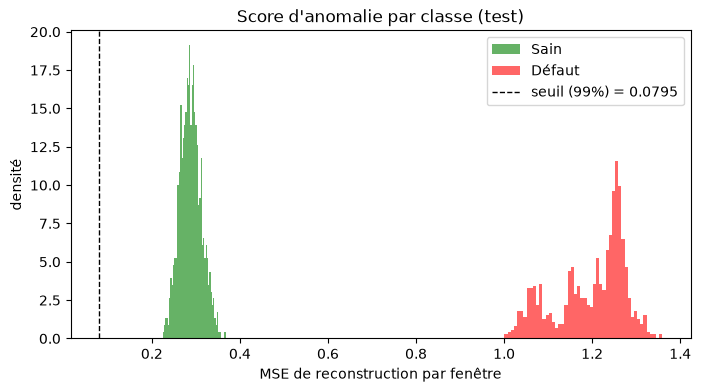

=== Matrice de confusion ===


,prédit sain,prédit défaut
réel sain,0,808
réel défaut,0,1011


FPR (fausses alarmes, sains détectés défaut) : 100.00%
FNR (défauts manqués, défauts prédits sains)  : 0.00%
=> test Norm
Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 204ms/step - loss: 0.0052 - val_loss: 0.0046
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - loss: 0.0041 - val_loss: 0.0031
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step - loss: 0.0021 - val_loss: 8.5744e-04
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - loss: 0.0010 - val_loss: 9.6056e-04
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step - loss: 6.9347e-04 - val_loss: 6.5006e-04
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - loss: 6.2027e-04 - val_loss: 4.8058e-04
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
0.005361466
ROC-AUC detection sain/defaut test Brut: 1.000


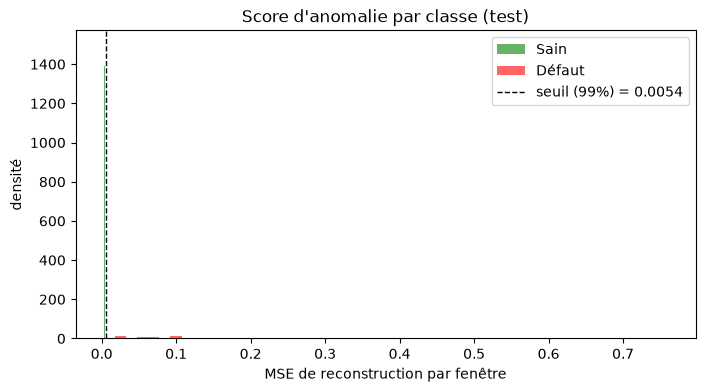

=== Matrice de confusion ===


,prédit sain,prédit défaut
réel sain,808,0
réel défaut,0,1011


FPR (fausses alarmes, sains détectés défaut) : 0.00%
FNR (défauts manqués, défauts prédits sains)  : 0.00%
=> test Brut


In [14]:
from keras.callbacks import EarlyStopping
from sklearn.metrics import roc_auc_score, confusion_matrix

# score d'anomalie MSE : erreur de reconstruction par fenetre
def score_anomalie(modele, SBNorm):
    Xr = modele.predict(SBNorm[..., None], verbose=1)[..., 0]
    return ((SBNorm - Xr) ** 2).mean(axis=1)            # Calcul de la MSE, notre score ici.

seuilPourcent = 99

for test in ["Norm", "Brut"]:
    X = SBNorm if test == "Norm" else SB
    X_train_sain = X[i_train][sain[i_train]]

    modele = models.conv1d_ae(SB.shape[1])                      # ← recréé à chaque tour
    ES = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, min_delta=0.02)
    hist = modele.fit(X_train_sain[..., None], X_train_sain[..., None],
                      epochs=50, batch_size=64, validation_split=0.1, verbose=1, callbacks=[ES])

    infos["score"+test] = score_anomalie(modele, X)              # score sur les mêmes données que le fit
    seuil = np.percentile(infos["score"+test].to_numpy()[i_train][sain[i_train]], 99)
    infos["alarme"+test] = infos["score"+test] > seuil

    print(seuil)

    y_test = (infos["defaut_sain"].to_numpy()[i_test] != "Sain")
    auc = roc_auc_score(y_test, infos["score"+test].to_numpy()[i_test])
    print(f"ROC-AUC detection sain/defaut test {test}: {auc:.3f}")


    # FIGURE 2 : distribution du score d'anomalie (MSE par fenêtre)
    scores = infos["score"+test].to_numpy()
    plt.figure(figsize=(8, 4))
    for classe, couleur in [("Sain", "green"), ("Défaut", "red")]:
        m = infos["defaut_sain"].to_numpy()[i_test] == classe
        plt.hist(scores[i_test][m], bins=50, density=True, alpha=0.6, label=classe, color=couleur)
    plt.axvline(seuil, color="black", ls="--", lw=1, label=f"seuil ({seuilPourcent}%) = {seuil:.4f}")
    plt.xlabel("MSE de reconstruction par fenêtre"); plt.ylabel("densité")
    plt.title("Score d'anomalie par classe (test)")
    plt.legend(); plt.show()



    y_true = (infos["defaut_sain"].to_numpy()[i_test] != "Sain").astype(int)   # 0=sain, 1=défaut
    y_pred = (infos["score"+test].to_numpy()[i_test] > seuil).astype(int)

    print("=== Matrice de confusion ===")
    display(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=[0, 1]), index=["réel sain", "réel défaut"], columns=["prédit sain", "prédit défaut"]))



    y_true = (infos["defaut_sain"].to_numpy()[i_test] != "Sain").astype(int)   # 1 = défaut
    y_pred = (infos["score"+test].to_numpy()[i_test] > seuil).astype(int)      # 1 = alarme

    TN, FP, FN, TP = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print(f"FPR (fausses alarmes, sains détectés défaut) : {FP/(FP+TN):.2%}")
    print(f"FNR (défauts manqués, défauts prédits sains)  : {FN/(FN+TP):.2%}")
    print(f"=> test {test}")